In [1]:
import numpy as np
import matplotlib.pyplot as plt


import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
from PDEModel import PNJunction as PNJ

calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData


---
## keeping imag theta_3 changes transmission for oblique incidence

#### three cases
* normal incidence --> doesn't matter (theta_3 = 0)
** wavefront are all 'past' the barrier

* oblique incidence, wlen > 160 nm (k_sio2 = 0), T = 1 - R instead of coupling * |t|
* oblique incidence, wlen < 160 nm. |t| coefficient w/ poynting vector? or calculate A explicitly from abs equation for EM loss


$$T_{s, p} = \frac{n_2 \cos\theta_2}{n_1 \cos\theta_1} |t_{s, p}|^2$$

$$R_{s, p} = |r_{s, p}|^2$$

In [2]:
## making some tools for these more involved optics calculations

eta = 376.6 # impedance of free space in ohms
def wavePhase(prefac, kVec, x, y, z):
    
    """Generate a wave vector with a given prefactor, wavevector, reference point, and phase."""
    return prefac * np.exp(1j * (kVec[0] * x + kVec[1] * y + kVec[2] * z))

    
# Find orthonormal basis: (e1=global_dir, e2, e3)
def orthonormal_basis_from_vector(v):
    v = v / np.linalg.norm(v)
    if abs(v[0]) < 0.9:
        other = np.array([1, 0, 0])
    else:
        other = np.array([0, 1, 0])
    e2 = np.cross(v, other)
    e2 /= np.linalg.norm(e2)
    e3 = np.cross(v, e2)
    return v, e2, e3

# print(orthonormal_basis_from_vector(np.array([1, 0, 0])))

## z axis is direction of propagation. z+ to the right. +x is up, y is out of the page.
## s polarization is E field along y-axis (perpendicular to the plane of incidence)
##   so b field is in the xz plane
## p polarization is E field along xz plane (parallel to the plane of incidence)
##   so b field is along y-axis
## use EScale = sqrt(eta/n1) for incoming magnitude = 1.0
class OpticalWave:
    def __init__(self, wlen, n, theta, EScale = 1.0):
        self.wavelength = wlen
        self.n = n
        self.Y = self.n/eta
        self.scaleE = EScale
        
        self.theta = theta
        self.k0 = n * 2 * np.pi / wlen # k0 includes the refractive index
        # self.polarization = polarization
        
        self.ki = np.array([-self.k0 * np.sin(self.theta),
                            0,
                            self.k0 * np.cos(self.theta)])  # incident wavevector
        
        self.kr = np.array([-self.k0 * np.sin(self.theta),
                            0,
                            -self.k0 * np.cos(self.theta)]) # reflected wavevector
        return
    
    
    ## we will work with E(r) = E0 * exp(i * k . r)
    ## so H = n/eta * E x k / |k| = Y * E x k / |k|
    def polarize(self, p):
        """Set the polarization of the wave."""
        self.polarization = p
        
        if p == 's':
            self.Evec = np.array([0, 1, 0])  # s-polarized electric field (E field along y-axis)
            self.Bvec = np.array([-np.cos(self.theta), 0, np.sin(self.theta)])
        elif p == 'p':
            self.Evec = np.array([np.cos(self.theta), 0, np.sin(self.theta)]) # E field in x, z plane
            self.Bvec = np.array([0, 1, 0])
        return
    
    def fullWaveVec_i(self, x, y, z, field=1.0):
        """Generate the full 3d wave vector for the wave."""
        
        self.Ei_phase = wavePhase(field * self.scaleE, self.ki, x, y, z)
        self.Hi_phase = self.Y * self.Ei_phase
        
        self.Ei_full = np.array([self.Evec[0] * self.Ei_phase,
                                self.Evec[1] * self.Ei_phase,
                                self.Evec[2] * self.Ei_phase], dtype=complex)
        
        self.Hi_full = np.array([self.Bvec[0] * self.Hi_phase,
                                self.Bvec[1] * self.Hi_phase,
                                self.Bvec[2] * self.Hi_phase], dtype=complex)
        return
    
    def RefWaveVec(self, x, y, z, field=1.0):
        self.Er_phase = wavePhase(field * self.scaleE, self.kr, x, y, z)
        self.Hr_phase = self.Y * self.Er_phase

        self.Er_full = np.array([self.Evec[0] * self.Er_phase,
                                 self.Evec[1] * self.Er_phase,
                                 self.Evec[2] * self.Er_phase], dtype=complex)
        self.Hr_full = np.array([self.Bvec[0] * self.Hr_phase,
                                 self.Bvec[1] * self.Hr_phase,
                                 self.Bvec[2] * self.Hr_phase], dtype=complex)
        return
    
    def Poynting_Vector(self):
        """Calculate the Poynting vector from the electric and magnetic fields."""
        self.S_full = np.cross(self.Ei_full, self.Hi_full, axis=0)
        self.S_real = np.real(np.cross(self.Ei_full, np.conj(self.Hi_full), axis=0))
        self.sAngle = np.mean(np.arctan2(self.S_real[0], self.S_real[2]))
        self.sImagAngle = np.mean(np.arctan2(self.S_full[1].imag, self.S_full[2].imag))
        return self.S_real

    def buildsHat(self):
        """Calculate the unit vector in the direction of the Poynting vector."""
        sAvg = np.mean(self.S_real, axis=(1, 2, 3))
        return sAvg / np.linalg.norm(sAvg)

    def Poynting_VectorRef(self):
        """Calculate the Poynting vector for the reflected wave."""
        self.Sr_full = np.cross(self.Er_full, self.Hr_full, axis=0)
        self.Sr_real = np.real(np.cross(self.Er_full, np.conj(self.Hr_full), axis=0))
        self.srAngle = np.mean(np.arctan2(self.Sr_real[0], self.Sr_real[2]))
        self.srImagAngle = np.mean(np.arctan2(self.Sr_full[1].imag, self.Sr_full[2].imag))
        return self.Sr_real

    ## using S_real and the xyz coordinates, i want to find the z magnitude of the poynting vector for a
    ## slice perpendicular to the beam. so average magnitude of a slice perpendicular to S_real, not just a simple slice in z

class Interface:
    def __init__(self, n1, n2, theta1, real2 = False, pickPol = None):
        self.n1 = n1
        self.n2 = n2
        self.theta1 = theta1
        self.theta2 = ME.Snells_Law(n1=n1, n2=n2, theta1=theta1)
        if real2:
            self.theta2 = np.real(self.theta2)

        self.coupling = np.real(self.n2 * np.cos(self.theta2))/np.real(self.n1 * np.cos(self.theta1))
        # self.couplingP = np.real(self.n2 * np.cos(self.theta1))/np.real(self.n1 * np.cos(self.theta2))
        # self.coupling = np.real(self.n2 * np.cos(self.theta2)/(self.n1 * np.cos(self.theta1)))
        # self.pCoupling = np.real(self.n2 * np.cos(self.theta1))/np.real(self.n1 * np.cos(self.theta2))
        
        self.ac = np.real(np.cos(self.theta2)/np.cos(self.theta1))

        # Fresnel coefficients
        self.rs, self.rp, self.ts, self.tp = ME.Fresnel_Coefficients(n1=n1, n2=n2, theta1=theta1, theta2=self.theta2)
        if pickPol is not None:
            self.pOption = pickPol
        return
    
    def pickPol(self, pOption):
        self.pOption = pOption
        
    def getFieldTerms(self):
        if self.pOption == 's':
            return self.rs, self.ts
        elif self.pOption == 'p':
            return self.rp, self.tp

    def FresnelRT(self):
        if self.pOption == 's':
            return np.abs(self.rs)**2, self.coupling * np.abs(self.ts)**2
        elif self.pOption == 'p':
            return np.abs(self.rp)**2, self.coupling * np.abs(self.tp)**2
        
    # def SpecialP_T(self):
    #     thisCoupling = np.real(self.n2 * np.cos(self.theta2)/(self.n1 * np.cos(self.theta1)))
    #     tTerm = np.abs(self.tp/(np.cos(self.theta2)/np.cos(self.theta1)))**2
    #     return thisCoupling * tTerm
        

## some methods for calculating things for a 3d vector field

def PlaneWave_zPoyntinPower(field3d):
    return np.mean(field3d[2])

def PlaneWave_magnitude(field3d):
    return np.mean(np.sqrt(field3d[0]**2 + field3d[1]**2 + field3d[2]**2))

def ZmagAlongWavefront(field3d, vector, x, y, z, spot = np.array([0.0, 0.0, 0.])):
   
    ## old way
    # """Calculate the magnitude of the Poynting vector along the plane perpendicular to vector (which will be sHat)."""
    # vHat = vector / np.linalg.norm(vector)
    # r_vec = np.stack([x, y, z], axis = 0)
    # r_along_kt = np.tensordot(vHat, r_vec, axes=1)
    # wavefrontVal = np.min(r_along_kt - zSpot)
    # mask = np.isclose(r_along_kt, wavefrontVal, atol = 1e-3)
    
    ## new way
    # Unit vector along the wave direction
    vHat = vector / np.linalg.norm(vector)
    
    # Reference point
    ref_point = np.array(spot)

    # Coordinates relative to reference point
    r_vec = np.stack([x, y, z], axis=0)  # shape [3, Nx, Ny, Nz]
    r_rel = r_vec - ref_point[:, None, None, None]
    
    # Projection onto vHat
    r_along_vHat = np.tensordot(vHat, r_rel, axes=1)  # shape [Nx, Ny, Nz]

    # Find the plane index closest to zero distance
    flat_idx = np.argmin(np.abs(r_along_vHat))
    closest_val = r_along_vHat.flat[flat_idx]
    
    # Mask for that plane
    mask = np.isclose(r_along_vHat, closest_val, atol=1e-3)
    
    ##
    S_z_wavefront = np.mean(field3d[2][mask])
    Smag_at_wavefront = np.sqrt(field3d[0][mask]**2 + field3d[1][mask]**2 + field3d[2][mask]**2)

    return S_z_wavefront, Smag_at_wavefront


In [3]:
## controls
if1 = Interface(n1=1.3, n2=3.0 + 1.j, theta1=75/rad2deg)
if1.pickPol('p')
wlen = 25

xySpace = 100
z1Space = 10
z2Space = 10
nPoints = 50
n2Points = 50
X, Y, Z1 = np.meshgrid(np.linspace(-xySpace, xySpace, nPoints), np.linspace(-xySpace, xySpace, nPoints), np.linspace(-z1Space, 0, nPoints))  # meshgrid for x, y, z
X2, Y2, Z2 = np.meshgrid(np.linspace(-xySpace, xySpace, n2Points), np.linspace(-xySpace, xySpace, n2Points), np.linspace(0.0, z2Space, n2Points))  # meshgrid for x, y, z

## incident wave
e0 = np.sqrt(eta / if1.n1)  # Scale factor for electric field amplitude
Ei = OpticalWave(wlen, if1.n1, if1.theta1, EScale=e0)
Ei.polarize(if1.pOption)  # s-polarized wave
Ei.fullWaveVec_i(X, Y, Z1, field = 1.0)
si = Ei.Poynting_Vector()

## reflected wave
Ei.RefWaveVec(X, Y, Z1, field = if1.getFieldTerms()[0])  # calculate reflected wave vector
sr = Ei.Poynting_VectorRef()  # calculate Poynting vector for reflected wave

izPower = PlaneWave_zPoyntinPower(Ei.S_real)
iPower = PlaneWave_magnitude(Ei.S_real)  # total Poynting vector magnitude for incident wave

# print(izPower)
# print(iPower)

rzPower = PlaneWave_zPoyntinPower(Ei.Sr_real)  # Poynting vector z component for reflected wave
rPower = PlaneWave_magnitude(Ei.Sr_real)  # total Poynting vector magnitude for reflected wave

print("reflected components (plane waves)")
print(rzPower/izPower)
print(rPower/iPower)

if if1.pOption == 's':
    print("\nFresnel:",if1.FresnelRT(), 1 - np.sum(if1.FresnelRT()))
elif if1.pOption == 'p':
    print("\nFresnel:",if1.FresnelRT(), 1 - np.sum(if1.FresnelRT()))

# transmitted wave
Et = OpticalWave(wlen, if1.n2, if1.theta2, EScale=e0)
Et.polarize(if1.pOption)
Et.fullWaveVec_i(X2, Y2, Z2, if1.getFieldTerms()[1])  # transmitted wave vector
st = Et.Poynting_Vector()  # calculate Poynting vector for transmitted wave

print("St angle:", Et.sAngle*rad2deg, "theta2:", if1.theta2*rad2deg)

tzPower = PlaneWave_zPoyntinPower(Et.S_real)  # Poynting vector z component for transmitted wave
tPower = PlaneWave_magnitude(Et.S_real)  # total Poynting vector magnitude for transmitted wave

print("\ntransmitted components (average)")
print(tzPower/izPower)
print(tPower/iPower * if1.ac)

sHat = Et.buildsHat()
zAtWavefront = ZmagAlongWavefront(Et.S_real, sHat, X2, Y2, Z2, spot=[max(X2.flatten()), max(Y2.flatten()), 0])
# print(zAtWavefront[0])
## angled wavefront z component

print("\npoynting slices")
T_perp = np.mean(zAtWavefront[0])/izPower
Tmag_perp = np.mean(zAtWavefront[1])/iPower * if1.ac

print("wavefront slice, z T:", T_perp)
print("wavefront slice, mag T:", Tmag_perp)

print("\nz total:", T_perp + rzPower/izPower)
print("mag total:", Tmag_perp + rzPower/izPower)

reflected components (plane waves)
0.05672454785806679
0.05672454785806679

Fresnel: (0.056724547858066764, 0.9099334725933069) 0.03334197954862628
St angle: -19.359673230809427 theta2: (21.919707236824184-7.731810441148259j)

transmitted components (average)
0.17800242429926144
0.1766272880933769

poynting slices
wavefront slice, z T: 0.9432754521419281
wavefront slice, mag T: 0.9359882916919011

z total: 0.9999999999999949
mag total: 0.9927128395499679


In [4]:
## Using Poynting vector

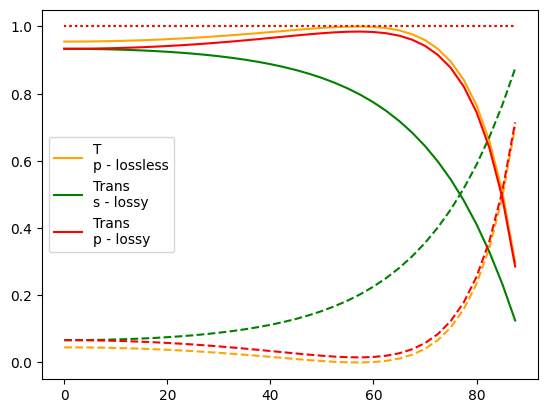

In [7]:

angles = np.arange(0, 89, 2.5)

if1 = Interface(n1=1.3, n2=2.0 + 0.0j, theta1=angles/rad2deg)
if2 = Interface(n1=1.3, n2=2.0 + 0.5j, theta1=angles/rad2deg, real2 = True)
"""
if1.pickPol('s')
c1 = 'blue'
plt.plot(angles, if1.FresnelRT()[1], color=c1, label = "Trans\ns - lossless")
plt.plot(angles, if1.FresnelRT()[0], linestyle = '--', color=c1)
plt.plot(angles, np.sum(if1.FresnelRT(), axis = 0), linestyle = ':', label='R + T', color=c1)
"""

c2 = 'orange'
if1.pickPol('p')
plt.plot(angles, if1.FresnelRT()[1], color=c2, label = "T\np - lossless")
plt.plot(angles, if1.FresnelRT()[0], linestyle = '--', color=c2)
plt.plot(angles, np.sum(if1.FresnelRT(), axis = 0), linestyle = ':', color=c2)

if2.pickPol('s')
c3 = 'green'
plt.plot(angles, if2.FresnelRT()[1], color=c3, label = "Trans\ns - lossy")
plt.plot(angles, if2.FresnelRT()[0], linestyle = '--', color=c3)
plt.plot(angles, np.sum(if2.FresnelRT(), axis = 0), linestyle = ':', color=c3)

if2.pickPol('p')
c4 = 'red'
plt.plot(angles, if2.FresnelRT()[1], color=c4, label = "Trans\np - lossy")
plt.plot(angles, if2.FresnelRT()[0], linestyle = '--', color=c4)
plt.plot(angles, np.sum(if2.FresnelRT(), axis = 0), linestyle = ':', color=c4)

# plt.plot(angles, if2.FresnelRT()[1], color=c4, label = "Trans\np - lossy")
# plt.plot(angles, if2.SpecialP_T(), linestyle='--', color='purple', label='Special T')

# plt.hlines(0, xmin=0, xmax=90, color='k', linestyle='--')
plt.legend()

4.440892098500626e-16


Text(0.5, 0, '$\\theta_1$ (degrees)')

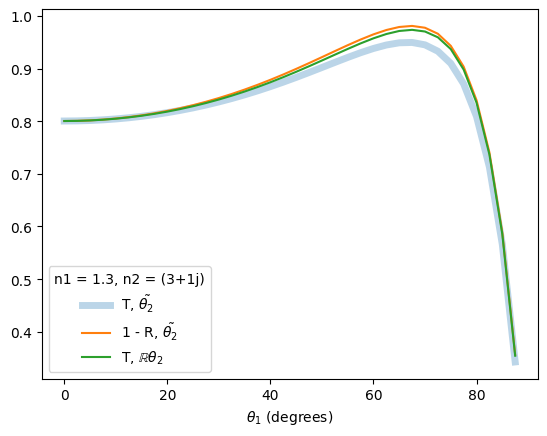

In [8]:
# plot real transmission for real theta2 vs 1-R

ifi = Interface(n1=1.3, n2=3.0 + 1.j, theta1=angles/rad2deg, pickPol="p")
ifReal = Interface(n1=1.3, n2=3.0 + 1.j, theta1=angles/rad2deg, real2=True, pickPol='p')

plt.plot(angles, ifi.FresnelRT()[1], label = r"T, $\tilde{\theta_2}$", linewidth = 5, alpha = 0.3)
plt.plot(angles, 1 - ifi.FresnelRT()[0], label=r'1 - R, $\tilde{\theta_2}$')
# plt.plot(angles, ifReal.FresnelRT()[1], label=r'T, $\mathbb{R} \theta_2$')
plt.plot(angles, ifReal.FresnelRT()[1], label=r'T, $\mathbb{R} \theta_2$')

plt.legend(title = f"n1 = {ifi.n1}, n2 = {ifi.n2}")

print(max(ifReal.FresnelRT()[1] - (1-ifReal.FresnelRT()[0])))

plt.xlabel(r'$\theta_1$ (degrees)')